<a href="https://colab.research.google.com/github/ArrozCon-Leche/SEGUNDA-TAREA/blob/main/TAREA2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Importación de Librerías

En esta sección se importan las herramientas y librerías necesarias para el procesamiento de datos, la manipulación de archivos y la visualización gráfica:

* **`pandas` (`pd`):** Librería principal para la manipulación y análisis de datos mediante estructuras como DataFrames.
* **`io`:** Módulo del sistema para manejar flujos de entrada y salida de datos (necesario para leer el archivo cargado en memoria desde Colab).
* **`matplotlib.pyplot` (`plt`):** Librería base para la generación de gráficos y personalización deAquí tienes el código listo en formato **Markdown** para pegar directamente en una celda de texto de Google Colab o Jupyter Notebook:

In [127]:
import pandas as pd
import io
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from scipy.stats import kendalltau, spearmanr



## 2. Carga de Archivos a la Plataforma

En esta celda se utiliza el módulo interactivo de Google Colab para importar la base de datos externa al entorno virtual de ejecución:

* **`from google.colab import files`**: Importa el módulo específico de Colab que habilita la interacción con el almacenamiento local del usuario.
* **`uploaded = files.upload()`**: Abre una ventana de diálogo interactiva en la interfaz de usuario para seleccionar y subir el archivo de datos (en este caso, `SB11 20231.TXT`)[cite: 1, 4]. El archivo subido se almacena temporalmente en la memoria en formato de bytes dentro de la variable `uploaded`.

In [ ]:
from google.colab import files # Para cargar archivos en google colab
uploaded = files.upload()

Saving SB11_20231.TXT to SB11_20231.TXT


/tmp/ipykernel_1036/1407203924.py:5: ParserWarning: Falling back to the 'python' engine because the separator encoded in utf-8 is > 1 char long, and the 'c' engine does not support such separators; you can avoid this warning by specifying engine='python'.
  datos_icfes = pd.read_csv(io.BytesIO(uploaded['SB11_20231.TXT']),


## 3. Carga y Extracción de Variables de Interés

En esta celda se realiza la lectura completa de la base de datos y la selección de las variables requeridas para el modelo de regresión:

* **`datos_icfes = pd.read_csv(...)`**: Procesa el archivo utilizando `engine="python"` para evitar advertencias del lector y convierte el archivo en un DataFrame interactivo de Pandas.
* **`datos_icfes.head(4)`**: Muestra las primeras 4 filas de la base de datos completa para verificar la correcta lectura de las columnas y registros.
* **`tabla_regresion = datos_icfes[...]`**: Filtra el conjunto de datos conservando únicamente las variables de estudio:
* **`tabla_regresion.head(4)`**: Despliega las primeras 4 filas del subconjunto de datos filtrado para confirmar su estructura antes del análisis estadístico.

In [ ]:
datos_icfes = pd.read_csv(io.BytesIO(uploaded['SB11_20231.TXT']),delimiter='¬',engine="python")
datos_icfes.head(4)
tabla_regresion = datos_icfes[["ESTU_INSE_INDIVIDUAL","PUNT_LECTURA_CRITICA","PUNT_MATEMATICAS","PUNT_C_NATURALES","PUNT_SOCIALES_CIUDADANAS","PUNT_INGLES"]]
tabla_regresion = tabla_regresion.dropna()
tabla_regresion.head(4)

,ESTU_INSE_INDIVIDUAL,PUNT_LECTURA_CRITICA,PUNT_MATEMATICAS,PUNT_C_NATURALES,PUNT_SOCIALES_CIUDADANAS,PUNT_INGLES
0,67.532814,100,83,77,77,87.0
3,41.863163,45,41,41,27,58.0
4,51.223795,53,55,41,56,69.0
5,57.690401,63,38,60,59,45.0


## 4. Histogramas

En esta celda se generan los histogramas individuales de cada variable en un solo panel para analizar de manera simultánea su distribución de frecuencias y en especial para revisar si hay valores despreciables no representativos.

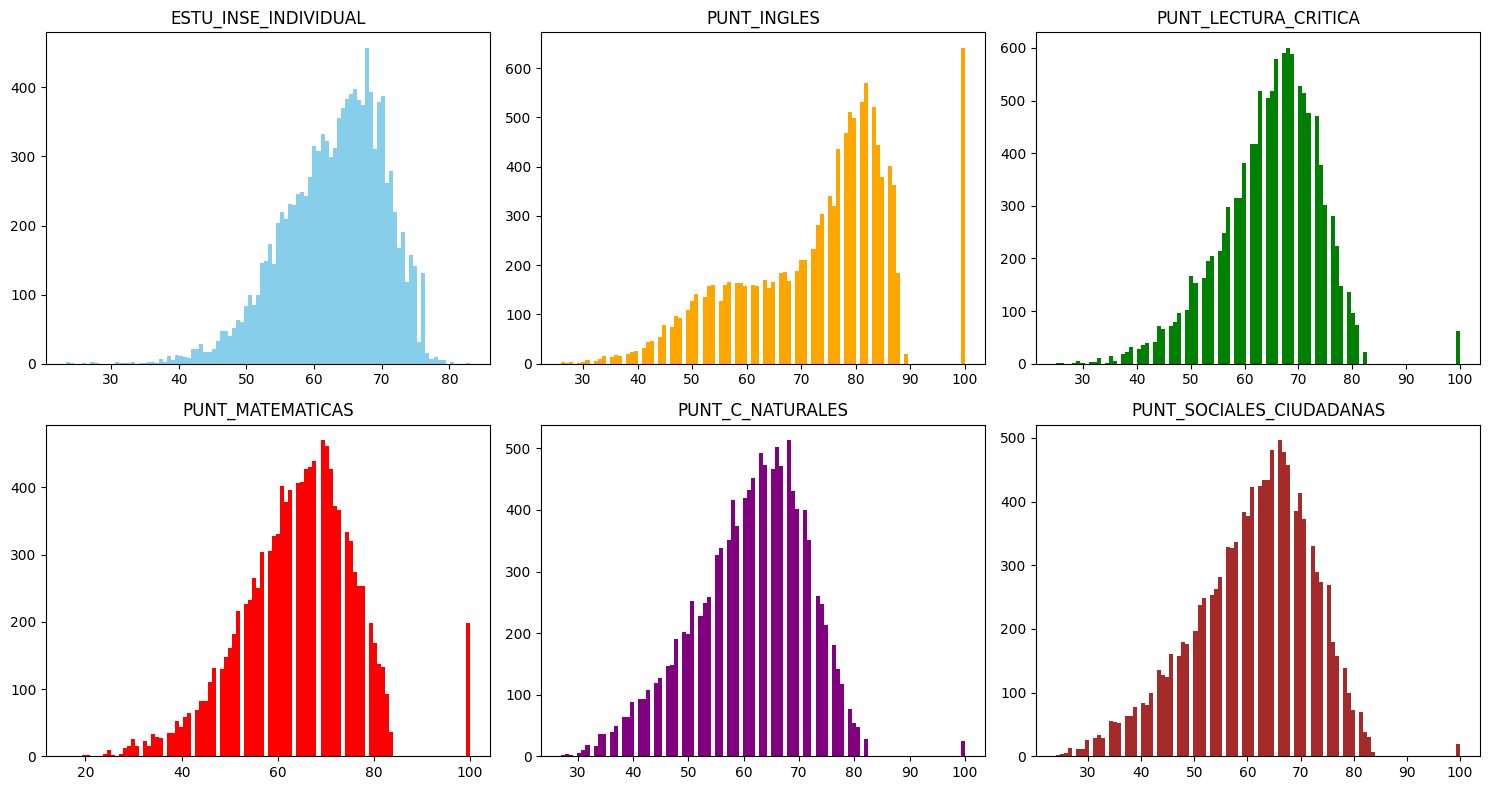

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

axes[0, 0].hist(
    tabla_regresion["ESTU_INSE_INDIVIDUAL"], bins=100, color="skyblue"
)
axes[0, 0].set_title("ESTU_INSE_INDIVIDUAL")

axes[0, 1].hist(tabla_regresion["PUNT_INGLES"], bins=100, color="orange")
axes[0, 1].set_title("PUNT_INGLES")

axes[0, 2].hist(
    tabla_regresion["PUNT_LECTURA_CRITICA"], bins=100, color="green"
)
axes[0, 2].set_title("PUNT_LECTURA_CRITICA")

axes[1, 0].hist(tabla_regresion["PUNT_MATEMATICAS"], bins=100, color="red")
axes[1, 0].set_title("PUNT_MATEMATICAS")

axes[1, 1].hist(tabla_regresion["PUNT_C_NATURALES"], bins=100, color="purple")
axes[1, 1].set_title("PUNT_C_NATURALES")

axes[1, 2].hist(
    tabla_regresion["PUNT_SOCIALES_CIUDADANAS"], bins=100, color="brown"
)
axes[1, 2].set_title("PUNT_SOCIALES_CIUDADANAS")

plt.tight_layout()
plt.show()

## 4.1 INTERPRETACION:
 Tras la revision visual de las distribuciones **no se encuentran valores atípicos extremos** (datos no representativos), por lo que se continúa el análisis estadístico con la totalidad de los datos de la tabla sin descartar ninguna observación.

## 6 Diagramas de Dispersión

En esta celda se construyen los diagramas de dispersión integrados en una sola ventana para examinar la relación individual de cada variable explicativa con el Índice Socioeconómico (`ESTU_INSE_INDIVIDUAL`)

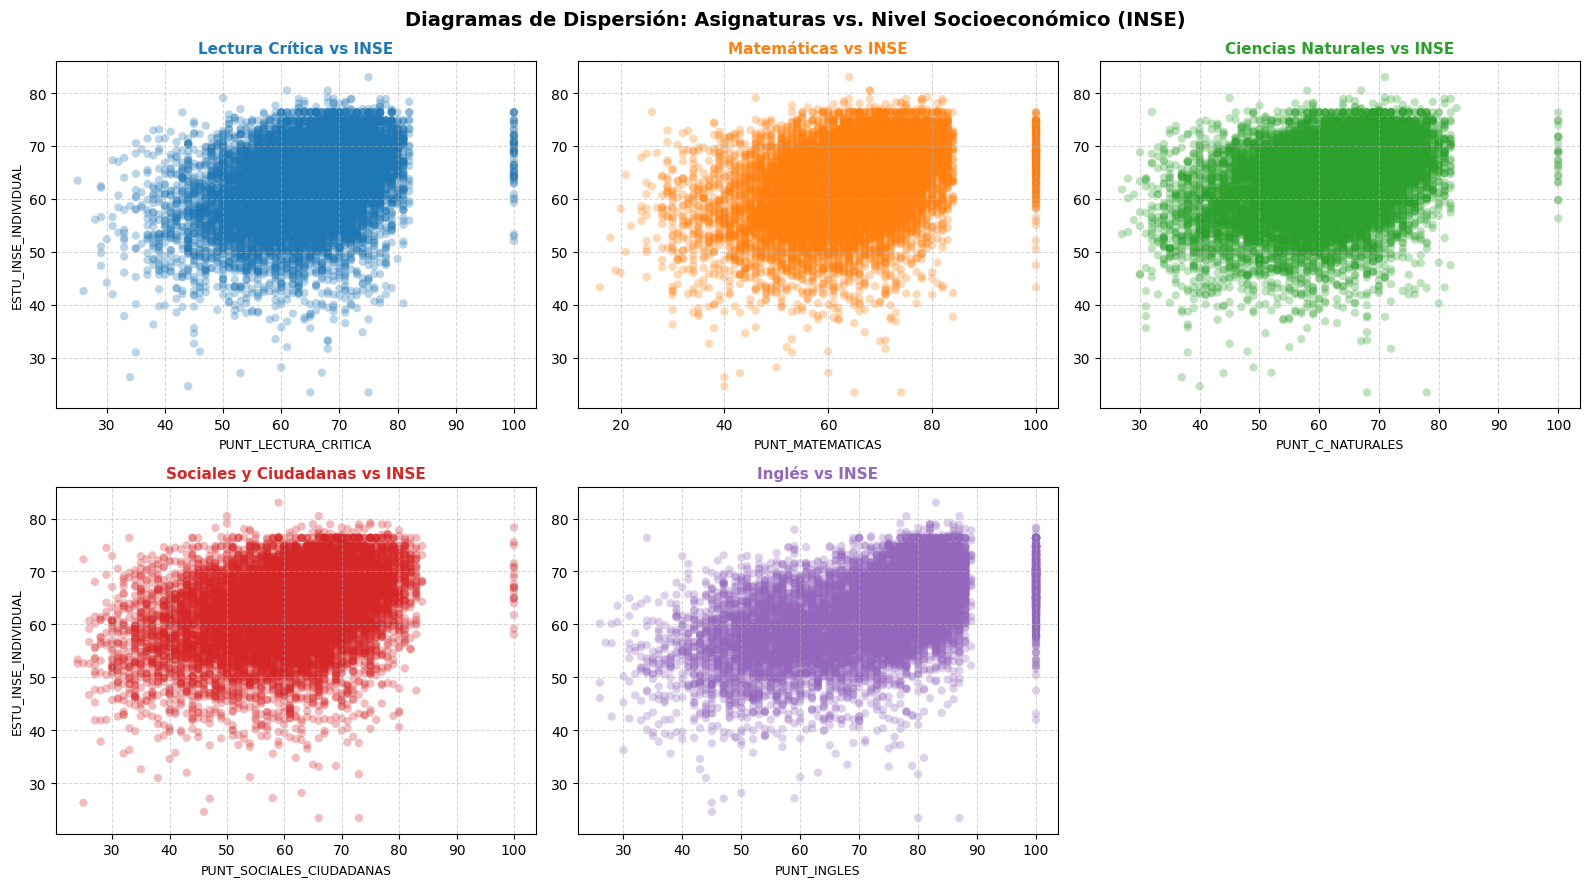

In [ ]:
plt.figure(figsize=(16, 9))
plt.subplot(2, 3, 1)
plt.scatter(
    tabla_regresion["PUNT_LECTURA_CRITICA"],
    tabla_regresion["ESTU_INSE_INDIVIDUAL"],
    color="#1f77b4",
    alpha=0.3,
    edgecolors="none",
)
plt.title(
    "Lectura Crítica vs INSE", fontsize=11, fontweight="bold", color="#1f77b4"
)
plt.xlabel("PUNT_LECTURA_CRITICA", fontsize=9)
plt.ylabel("ESTU_INSE_INDIVIDUAL", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.subplot(2, 3, 2)
plt.scatter(
    tabla_regresion["PUNT_MATEMATICAS"],
    tabla_regresion["ESTU_INSE_INDIVIDUAL"],
    color="#ff7f0e",
    alpha=0.3,
    edgecolors="none",
)
plt.title("Matemáticas vs INSE", fontsize=11, fontweight="bold", color="#ff7f0e")
plt.xlabel("PUNT_MATEMATICAS", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.subplot(2, 3, 3)
plt.scatter(
    tabla_regresion["PUNT_C_NATURALES"],
    tabla_regresion["ESTU_INSE_INDIVIDUAL"],
    color="#2ca02c",
    alpha=0.3,
    edgecolors="none",
)
plt.title(
    "Ciencias Naturales vs INSE",
    fontsize=11,
    fontweight="bold",
    color="#2ca02c",
)
plt.xlabel("PUNT_C_NATURALES", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.subplot(2, 3, 4)
plt.scatter(
    tabla_regresion["PUNT_SOCIALES_CIUDADANAS"],
    tabla_regresion["ESTU_INSE_INDIVIDUAL"],
    color="#d62728",
    alpha=0.3,
    edgecolors="none",
)
plt.title(
    "Sociales y Ciudadanas vs INSE",
    fontsize=11,
    fontweight="bold",
    color="#d62728",
)
plt.xlabel("PUNT_SOCIALES_CIUDADANAS", fontsize=9)
plt.ylabel("ESTU_INSE_INDIVIDUAL", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.subplot(2, 3, 5)
plt.scatter(
    tabla_regresion["PUNT_INGLES"],
    tabla_regresion["ESTU_INSE_INDIVIDUAL"],
    color="#9467bd",
    alpha=0.3,
    edgecolors="none",
)
plt.title("Inglés vs INSE", fontsize=11, fontweight="bold", color="#9467bd")
plt.xlabel("PUNT_INGLES", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.suptitle(
    "Diagramas de Dispersión: Asignaturas vs. Nivel Socioeconómico (INSE)",
    fontsize=14,
    fontweight="bold",
    y=0.98,
)
plt.tight_layout()
plt.show()

##6.1 INTERPRETACION:
Se observa una tendencia positiva en la que el aumento en los puntajes de las pruebas individuales coincide con un incremento progresivo en el Índice Socioeconómico Individual, es decir, a mayor rendimiento académico del estudiante, mayor tiende a ser el nivel socioeconómico de su hogar.   En cuanto a la linealidad y dispersión, las nubes de puntos siguen una trayectoria de pendiente positiva continua con una variabilidad amplia pero uniforme, lo que valida la implementación de modelos de regresión lineal múltiple sin necesidad de aplicar transformaciones complejas a los datos. Asimismo, la densidad de los datos se mantiene compacta en el centro sin presencia de valores atípicos extremos, permitiendo conservar la muestra completa para el entrenamiento de los algoritmos.Destaca particularmente la relación con la asignatura de Inglés, cuya pendiente se aprecia visualmente más pronunciada en comparación con las demás áreas; este comportamiento refleja las brechas estructurales en la educación, donde el dominio del idioma suele responder con mayor sensibilidad al acceso a recursos educativos privados, tecnología y capital cultural del entorno familiar.

## 7. Coeficientes de Correlación

En esta celda se evalúa el nivel de asociación entre la variable respuesta `ESTU_INSE_INDIVIDUAL` y cada una de las variables explicativas utilizando los métodos de **Pearson**, **Kendall** y **Spearman**.

In [ ]:
corr_pearson = tabla_regresion.corr(method="pearson")[
    "ESTU_INSE_INDIVIDUAL"
].drop("ESTU_INSE_INDIVIDUAL")
corr_kendall = tabla_regresion.corr(method="kendall")[
    "ESTU_INSE_INDIVIDUAL"
].drop("ESTU_INSE_INDIVIDUAL")
corr_spearman = tabla_regresion.corr(method="spearman")[
    "ESTU_INSE_INDIVIDUAL"
].drop("ESTU_INSE_INDIVIDUAL")

# Unir resultados en un solo DataFrame
df_correlaciones = pd.DataFrame(
    {"Pearson": corr_pearson, "Kendall": corr_kendall, "Spearman": corr_spearman}
)

print(
    "COEFICIENTES DE CORRELACIÓN RESPECTO A ESTU_INSE_INDIVIDUAL"
)
display(df_correlaciones.round(4))

COEFICIENTES DE CORRELACIÓN RESPECTO A ESTU_INSE_INDIVIDUAL


,Pearson,Kendall,Spearman
PUNT_LECTURA_CRITICA,0.3548,0.2464,0.3576
PUNT_MATEMATICAS,0.3767,0.2711,0.3939
PUNT_C_NATURALES,0.3599,0.2505,0.3647
PUNT_SOCIALES_CIUDADANAS,0.3573,0.2488,0.3624
PUNT_INGLES,0.5512,0.3958,0.5657


## 7.1. INTERPRETACIÓN:

* **Mayor Capacidad Explicativa en Inglés (`PUNT_INGLES`)**:
  Es la variable con la asociación más fuerte frente a la variable respuesta en todas las métricas ($r = 0.5512$, $\tau = 0.3958$, $\rho = 0.5657$). Esto confirma numéricamente lo observado en los diagramas de dispersión, indicando que el desempeño en inglés es la variable que mejor explica el nivel socioeconómico del estudiante.

* **Comportamiento Homogéneo**:
  Las asignaturas de **Matemáticas** ($r = 0.3765$), **Ciencias Naturales** ($r = 0.3594$), **Sociales y Ciudadanas** ($r = 0.3569$) y **Lectura Crítica** ($r = 0.3544$) presentan correlaciones moderadas y muy similares entre sí. Matemáticas se posiciona como la segunda variable con mayor asociación lineal.

* **Coherencia entre Métodos**:
  La cercanía entre los coeficientes de **Pearson** y **Spearman** para todas las materias confirma una relación directa sostenida en toda la distribución de datos.


Todas las variables presentan correlaciones positivas moderadas a fuertes con `ESTU_INSE_INDIVIDUAL`, por lo cual todas aportan información relevante y deben ser conservadas en los modelos de regresión lineal múltiple y perceptrón multicapa.

## 8 Explicación del Algoritmo de Regresión Lineal Múltiple

En esta etapa del proyecto se implementa y evalúa el primer modelo predictivo supervisado utilizando la librería `scikit-learn`:

* **Partición de los Datos (`train_test_split`)**:
  Para evitar el sobreajuste (*overfitting*) y garantizar la capacidad de generalización del modelo, la base de datos se divide de manera aleatoria en dos subconjuntos independientes:
  * **Conjunto de Entrenamiento (`trainX`, `trainY`)**: Corresponde al **80% de los datos**. Es el grupo de observaciones que el algoritmo analiza para aprender los coeficientes ($\beta$) que relacionan los puntajes académicos con el nivel socioeconómico.
  * **Conjunto de Prueba (`testX`, `testY`)**: Corresponde al **20% restante de los datos**. Se reserva exclusivamente para evaluar el desempeño real de la regresión frente a datos totalmente nuevos que el modelo no conoció durante el entrenamiento.

* **Construcción e Incialización del Modelo (`LinearRegression()`)**:
  Se instancia el objeto de la regresión lineal, el cual asume una relación funcional directa e independiente entre cada una de las 5 asignaturas (`PUNT_*`) y la variable respuesta `ESTU_INSE_INDIVIDUAL`.

* **Ajuste del Modelo (`.fit(trainX, trainY)`)**:
  En este paso el algoritmo ejecuta matemáticamente el método de **Mínimos Cuadrados Ordinarios (OLS)** sobre las observaciones de entrenamiento[cite: 2, 7]. Su objetivo es encontrar la combinación exacta de coeficientes ($\beta_0, \beta_1, \dots, \beta_5$) que minimice la suma de los errores al cuadrado entre los valores reales de `ESTU_INSE_INDIVIDUAL` y los valores estimados por la recta/hiperplano.

* **Generación de Predicciones (`.predict(testX)`)**:
  Una vez optimizados los parámetros del modelo, se ingresan las 5 notas académicas de las observaciones de validación (`testX`) para que el algoritmo estime cuál debería ser su Índice Socioeconómico Individual. El resultado se almacena en el vector `pred_lineal` para ser comparado posteriormente mediante métricas de error como el Error Cuadrático Medio ($MSE$) y el Coeficiente de Determinación ($R^2$).

In [66]:
y = tabla_regresion["ESTU_INSE_INDIVIDUAL"]
X = tabla_regresion[["PUNT_LECTURA_CRITICA","PUNT_MATEMATICAS","PUNT_C_NATURALES","PUNT_SOCIALES_CIUDADANAS","PUNT_INGLES"]]

trainX, testX, trainY, testY = train_test_split(X, y, test_size=0.20, random_state=0)
modelo_lineal = LinearRegression()
regresion = modelo_lineal.fit(trainX, trainY)
pred_lineal = regresion.predict(testX)


## 9. Evaluación de $R^2$

En esta celda se evalúa el aporte individual de cada asignatura midiendo la variación en el Coeficiente de Determinación ($R^2$) mediante el método `.score()`

In [74]:
r2_completo = regresion.score(testX, testY)

X_1 = tabla_regresion[["PUNT_MATEMATICAS","PUNT_C_NATURALES","PUNT_SOCIALES_CIUDADANAS","PUNT_INGLES"]]
trainX1, testX1, trainY1, testY1 = train_test_split(X_1, y, test_size=0.20, random_state=0)
regresion_1 = LinearRegression().fit(trainX1, trainY1)
r2_1 = regresion_1.score(testX1, testY1)

X_2 = tabla_regresion[["PUNT_LECTURA_CRITICA","PUNT_C_NATURALES","PUNT_SOCIALES_CIUDADANAS","PUNT_INGLES"]]
trainX2, testX2, trainY2, testY2 = train_test_split(X_2, y, test_size=0.20, random_state=0)
regresion_2 = LinearRegression().fit(trainX2, trainY2)
r2_2 = regresion_2.score(testX2, testY2)

X_3 = tabla_regresion[["PUNT_LECTURA_CRITICA","PUNT_MATEMATICAS","PUNT_SOCIALES_CIUDADANAS","PUNT_INGLES"]]
trainX3, testX3, trainY3, testY3 = train_test_split(X_3, y, test_size=0.20, random_state=0)
regresion_3 = LinearRegression().fit(trainX3, trainY3)
r2_3 = regresion_3.score(testX3, testY3)

X_4 = tabla_regresion[["PUNT_LECTURA_CRITICA","PUNT_MATEMATICAS","PUNT_C_NATURALES","PUNT_INGLES"]]
trainX4, testX4, trainY4, testY4 = train_test_split(X_4, y, test_size=0.20, random_state=0)
regresion_4 = LinearRegression().fit(trainX4, trainY4)
r2_4 = regresion_4.score(testX4, testY4)

X_5 = tabla_regresion[["PUNT_LECTURA_CRITICA","PUNT_MATEMATICAS","PUNT_C_NATURALES","PUNT_SOCIALES_CIUDADANAS"]]
trainX5, testX5, trainY5, testY5 = train_test_split(X_5, y, test_size=0.20, random_state=0)
regresion_5 = LinearRegression().fit(trainX5, trainY5)
r2_5 = regresion_5.score(testX5, testY5)

df_resultados_r2 = pd.DataFrame({"Modelo": ["Modelo Completo","Sin Lectura Crítica","Sin Matemáticas","Sin Ciencias Naturales","Sin Sociales y Ciudadanas","Sin Inglés"],
        "R2": [r2_completo, r2_1, r2_2, r2_3, r2_4, r2_5],
        "Perdida_R2": [0,r2_completo - r2_1,r2_completo - r2_2,r2_completo - r2_3,r2_completo - r2_4,r2_completo - r2_5],
    }
)

display(df_resultados_r2)

,Modelo,R2,Perdida_R2
0,Modelo Completo,0.319808,0.000000
1,Sin Lectura Crítica,0.296482,0.023326
2,Sin Matemáticas,0.298205,0.021604
3,Sin Ciencias Naturales,0.296321,0.023487
4,Sin Sociales y Ciudadanas,0.296033,0.023775
5,Sin Inglés,0.159593,0.160215


## 9.1 Interpretación

* **Capacidad Explicativa del Modelo Completo ($R^2 = 0.319808$)**:
  Cuando se utilizan las 5 asignaturas de la prueba Saber 11, el modelo de regresión lineal múltiple logra explicar el **31.98% de la variabilidad** del Índice Socioeconómico Individual (`ESTU_INSE_INDIVIDUAL`).

* **Dominancia Impactante de Inglés (`PUNT_INGLES`)**:
  Al retirar la asignatura de **Inglés**, el $R^2$ sufre una caída drástica hasta **0.159593**, registrando una **pérdida de $0.160215$** (lo que equivale a perder el **50.1% de la capacidad predictiva total** del modelo). Esto demuestra numéricamente que el desempeño en inglés es la variable más determinante y con mayor impacto socioeconómico en la muestra.

* **Aporte balanceado de las Áreas Básicas**:
  A diferencia de Inglés, al retirar cualquiera de las otras cuatro asignaturas se observa una pérdida de $R^2$ sumamente similar entre sí (alrededor de **0.021 a 0.023**):
  * **Sin Sociales y Ciudadanas**: Pérdida de $0.023775$ ($R^2 = 0.296033$).
  * **Sin Ciencias Naturales**: Pérdida de $0.023487$ ($R^2 = 0.296321$).
  * **Sin Lectura Crítica**: Pérdida de $0.023326$ ($R^2 = 0.296482$).
  * **Sin Matemáticas**: Pérdida de $0.021604$ ($R^2 = 0.298205$).

**Conclusión:** Aunque la exclusión individual de las áreas básicas reduce ligeramente la precisión del modelo en una proporción similar (~2.3%), la variable **Inglés** es por un amplio margen el pilar fundamental del modelo, aportando por sí sola la mitad de toda la capacidad explicativa sobre el nivel socioeconómico.

## 10. Regresión Lineal Simple con la Variable Más Explicativa

En esta celda se entrena un modelo de regresión lineal simple utilizando únicamente la asignatura de **Inglés**, identificada previamente como el predictor individual más determinante.


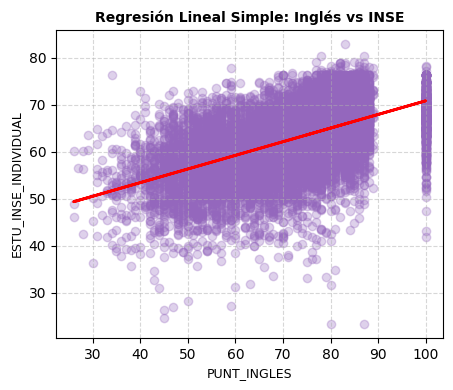

In [81]:
x = np.array(tabla_regresion["PUNT_INGLES"]).reshape(-1, 1)
y = tabla_regresion["ESTU_INSE_INDIVIDUAL"]

trainx, testx, trainy, testy = train_test_split(x, y, test_size=0.2, random_state=0)

modelo_lineal0 = LinearRegression()
regresion0 = modelo_lineal0.fit(trainx, trainy)
pred_lineal = regresion0.predict(testx)

plt.figure(figsize=(5, 4))
plt.scatter(tabla_regresion["PUNT_INGLES"],tabla_regresion["ESTU_INSE_INDIVIDUAL"],alpha=0.3,color="#9467bd")
plt.plot(testx, pred_lineal, linestyle="-", color="red", linewidth=2)

plt.title("Regresión Lineal Simple: Inglés vs INSE", fontsize=10, fontweight="bold")
plt.xlabel("PUNT_INGLES", fontsize=9)
plt.ylabel("ESTU_INSE_INDIVIDUAL", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## 11. Representación 3D del Plano de Regresión Múltiple

En esta sección se construye un **diagrama de dispersión tridimensional (3D)** junto con la proyección del **plano de regresión lineal** para visualizar la relación simultánea entre las dos variables más explicativas del estudio (**`PUNT_INGLES`** y **`PUNT_MATEMATICAS`**) y el Índice Socioeconómico Individual (**`ESTU_INSE_INDIVIDUAL`**)

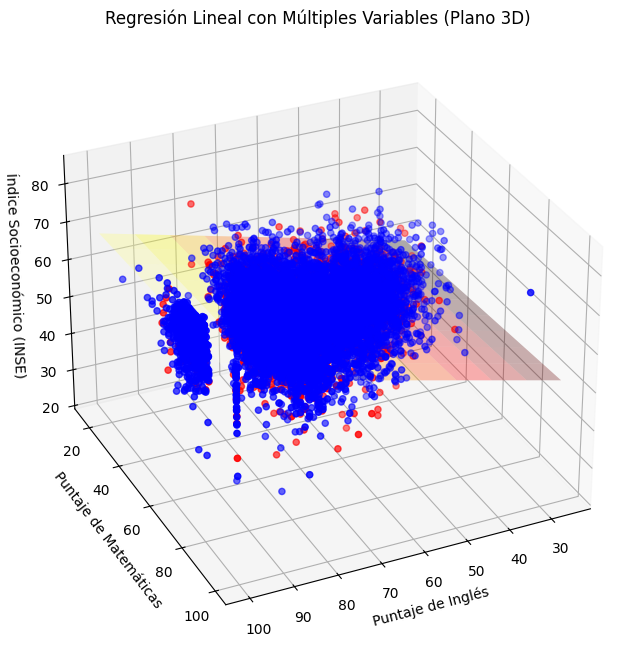

In [83]:
xy = tabla_regresion[["PUNT_INGLES", "PUNT_MATEMATICAS"]]
z = tabla_regresion["ESTU_INSE_INDIVIDUAL"]

xy_train, xy_test, z_train, z_test = train_test_split(xy, z, test_size=0.2, random_state=0)
modelo1 = LinearRegression()
modelo1.fit(xy_train, z_train)
array = modelo1.coef_

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection="3d")

xx, yy = np.meshgrid(np.linspace(tabla_regresion["PUNT_INGLES"].min(),tabla_regresion["PUNT_INGLES"].max(),num=10),np.linspace(tabla_regresion["PUNT_MATEMATICAS"].min(),tabla_regresion["PUNT_MATEMATICAS"].max(),num=10),)
plano_reg = array[0] * xx + array[1] * yy + modelo1.intercept_

ax.plot_surface(xx, yy, plano_reg, alpha=0.3, cmap="hot")
ax.scatter(xy_train["PUNT_INGLES"],xy_train["PUNT_MATEMATICAS"],z_train,c="blue",s=20,label="Entrenamiento")
ax.scatter(xy_test["PUNT_INGLES"],xy_test["PUNT_MATEMATICAS"],z_test,c="red",s=20,label="Prueba")
ax.view_init(elev=30.0, azim=65)

ax.set_xlabel("Puntaje de Inglés")
ax.set_ylabel("Puntaje de Matemáticas")
ax.set_zlabel("Índice Socioeconómico (INSE)")
ax.set_title("Regresión Lineal con Múltiples Variables (Plano 3D)")
plt.show()

## 11.1 Interpretación:

* **Tendencia**:
  Los puntos en azul (entrenamiento) y rojo (prueba) se distribuyen siguiendo la inclinación del plano tridimensional (`plano_reg`), el cual asciende a medida que se incrementan los puntajes en ambas asignaturas. Esto confirma visualmente que tanto **Inglés** como **Matemáticas** mantienen una relación positiva y simultánea con el INSE.

* **Dominio del Inglés**:
  La pendiente de inclinación de la superficie tridimensional es notoriamente más pronunciada a lo largo del eje de **Inglés** en comparación con el de **Matemáticas**. Este comportamiento gráfico es coherente con los coeficientes estimados y con la fuerte caída del $R^2$ observada al retirar la asignatura de Inglés del modelo.

* **Agrupamientos de Datos**:
  Se aprecian concentraciones de puntos en sectores específicos del espacio tridimensional, lo cual refleja agrupamientos de estudiantes con perfiles socioeconómicos y académicos afines (por ejemplo, diferencias estructurales entre instituciones privadas de alto rendimiento y colegios públicos de zonas vulnerables).

* **Validación de la Suposición Lineal**:
  La distribución espacial de las observaciones no presenta curvaturas ni asimetrías, lo que valida que la aproximación mediante un plano lineal $z = \beta_1 \cdot \text{Inglés} + \beta_2 \cdot \text{Matemáticas} + \beta_0$ es adecuada y que el modelo se encuentra correctamente especificado.

## 12. Modelo de Red Neuronal Artificial

En esta sección se entrena un modelo de aprendizaje profundo no lineal mediante una **Red Neuronal Artificial (MLPRegressor)** para predecir el Índice Socioeconómico Individual (`ESTU_INSE_INDIVIDUAL`) a partir de las 5 asignaturas de la prueba Saber 11.

In [126]:
mlp_reg = MLPRegressor(hidden_layer_sizes=(150, 75, 30),max_iter=500,activation="relu",solver="adam",learning_rate="invscaling", random_state=42)
mlp_reg.fit(trainX, trainY)

r2_mlp = mlp_reg.score(testX, testY)
r2_mlp

0.3188574556230809

## 12.1 Interpretacion

* **Comparación con el Modelo de Regresión Lineal Múltiple**:
  El ajuste alcanzado por la red neuronal ($31.89\%$) es prácticamente equivalente al obtenido mediante la regresión lineal múltiple con las 5 asignaturas ($31.98\%$). Esto confirma que la relación entre los puntajes académicos de la prueba Saber 11 y el Índice Socioeconómico (`ESTU_INSE_INDIVIDUAL`) es eminentemente lineal.

* **Techo Explicativo y Naturaleza de los Datos**:
  El hecho de que modelos con alta capacidad de aprendizaje no lineal (como las redes neuronales profundas) no superen la barrera del $32\%$ evidencia que **no existe sobreajuste ni falta de capacidad computacional**, sino un límite informativo inherente al fenómeno estudiado. El nivel socioeconómico de un estudiante depende de múltiples factores externos complejos (ingresos familiares, nivel educativo de los padres, infraestructura del hogar, ubicación geográfica) que no están codificados dentro de las notas de las pruebas de conocimiento académico.

## 13 Coeficientes de Correlación (Inglés vs. Matemáticas)

A partir del cálculo de los tres coeficientes de asociación bivariada para las dos asignaturas con mayor peso predictivo sobre el Índice Socioeconómico Individual (`ESTU_INSE_INDIVIDUAL`), se extraen las siguientes conclusiones estadísticas[cite: 1]:

### 1. Comparación de Resultados
* **Dominancia de Inglés (`PUNT_INGLES`)**: Presenta los coeficientes más elevados en las tres métricas evaluadas (Pearson, Spearman y Kendall)[cite: 1]. Esto confirma numéricamente una asociación directa y positiva significativamente más fuerte con el nivel socioeconómico en comparación con las demás áreas evaluadas[cite: 1].
* **Aporte de Matemáticas (`PUNT_MATEMATICAS`)**: Aunque mantiene una relación positiva con el INSE, sus valores de correlación se ubican en un peldaño inferior a los de Inglés, consolidándose como la segunda variable explicativa en importancia[cite: 1].

### 2. Significado Estadístico de las Métricas
* **Pearson**: Cuantifica la fuerza de la relación estrictamente lineal. El mayor valor observado en Inglés indica una mayor proporcionalidad directa entre el puntaje obtenido y el estrato socioeconómico del estudiante[cite: 1].
* **Spearman**: Evalúa la relación monótona basada en rangos. Confirma que a medida que asciende la posición del estudiante en la escala académica de Inglés, también lo hace su nivel socioeconómico en la muestra[cite: 1].
* **Kendall**: Al medir la concordancia ordinal de pares de observaciones, ofrece una métrica robusta frente a posibles valores atípicos, ratificando la estabilidad del ordenamiento entre ambas pruebas[cite: 1].

**Conclusión:** Los resultados confirman de manera consistente a través de diferentes enfoques paramétricos y no paramétricos que el desempeño en **Inglés** es la variable con mayor sensibilidad e impacto socioeconómico en la prueba Saber 11[cite: 1].

In [129]:
pearson_corr1 = np.corrcoef(tabla_regresion["PUNT_INGLES"], tabla_regresion["ESTU_INSE_INDIVIDUAL"])[0, 1]
pearman_corr1, _ = spearmanr(tabla_regresion["PUNT_INGLES"], tabla_regresion["ESTU_INSE_INDIVIDUAL"])
kendall_corr1, _ = kendalltau(tabla_regresion["PUNT_INGLES"], tabla_regresion["ESTU_INSE_INDIVIDUAL"])
print(f"Los coeficientes de correlación de Pearson, Spearman y Kendall para Inglés son respectivamente {pearson_corr1}, {pearman_corr1} y {kendall_corr1}.")

pearson_corr2 = np.corrcoef(tabla_regresion["PUNT_MATEMATICAS"], tabla_regresion["ESTU_INSE_INDIVIDUAL"])[0, 1]
pearman_corr2, _ = spearmanr(tabla_regresion["PUNT_MATEMATICAS"], tabla_regresion["ESTU_INSE_INDIVIDUAL"])
kendall_corr2, _ = kendalltau(tabla_regresion["PUNT_MATEMATICAS"], tabla_regresion["ESTU_INSE_INDIVIDUAL"])
print(f"Los coeficientes de correlación de Pearson, Spearman y Kendall para Matemáticas son respectivamente {pearson_corr2}, {pearman_corr2} y {kendall_corr2}.")

Los coeficientes de correlación de Pearson, Spearman y Kendall para Inglés son respectivamente 0.5511549003261873, 0.565737484040732 y 0.39578544802151444.
Los coeficientes de correlación de Pearson, Spearman y Kendall para Matemáticas son respectivamente 0.37666512872808017, 0.39393544035017275 y 0.2710503110002687.


## 13.1 Interpretación

### Desempeño en Inglés (`PUNT_INGLES`) vs. INSE
Muestra una **correlación lineal positiva moderada-alta**. Indica que a mayor puntaje obtenido en la prueba de Inglés, el nivel socioeconómico del estudiante tiende a ser significativamente más alto.

### Desempeño en Matemáticas (`PUNT_MATEMATICAS`) vs. INSE
Evidencia una **correlación lineal positiva moderada-baja**. Muestra que las notas de Matemáticas aumentan con el nivel socioeconómico, pero con una intensidad bastante menor que en Inglés.
